<a href="https://colab.research.google.com/github/bek180/computer-vision-projects/blob/main/FashionMNIST_Classification_with_PyTorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 206kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.77MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 7.58MB/s]


A1
Train images: 60000
Test images: 10000

A2
Images shape: torch.Size([64, 1, 28, 28])
Labels shape: torch.Size([64])

A3


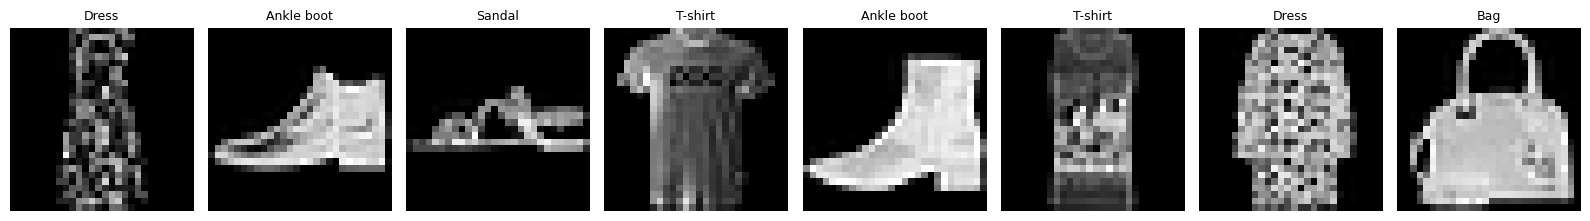


A4
Loss for target 0: 0.4170299470424652
Loss for target 2: 2.3170299530029297
Larger loss: 2

B1
Epoch 1 loss: 0.6831695068714969
Epoch 2 loss: 0.38089906357562364
Epoch 3 loss: 0.32516953650949354

B2
Trained model accuracy: 0.8757
Untrained model accuracy: 0.1339

B3
Epoch 1 loss: 0.6831695068714969
Epoch 2 loss: 0.38089906357562364
Epoch 3 loss: 0.32516953650949354
Epoch 4 loss: 0.29198093586035373
Epoch 5 loss: 0.26808818830038184


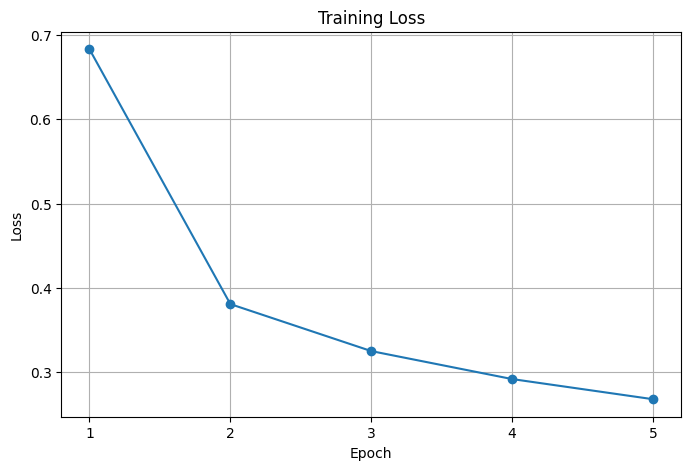


B4


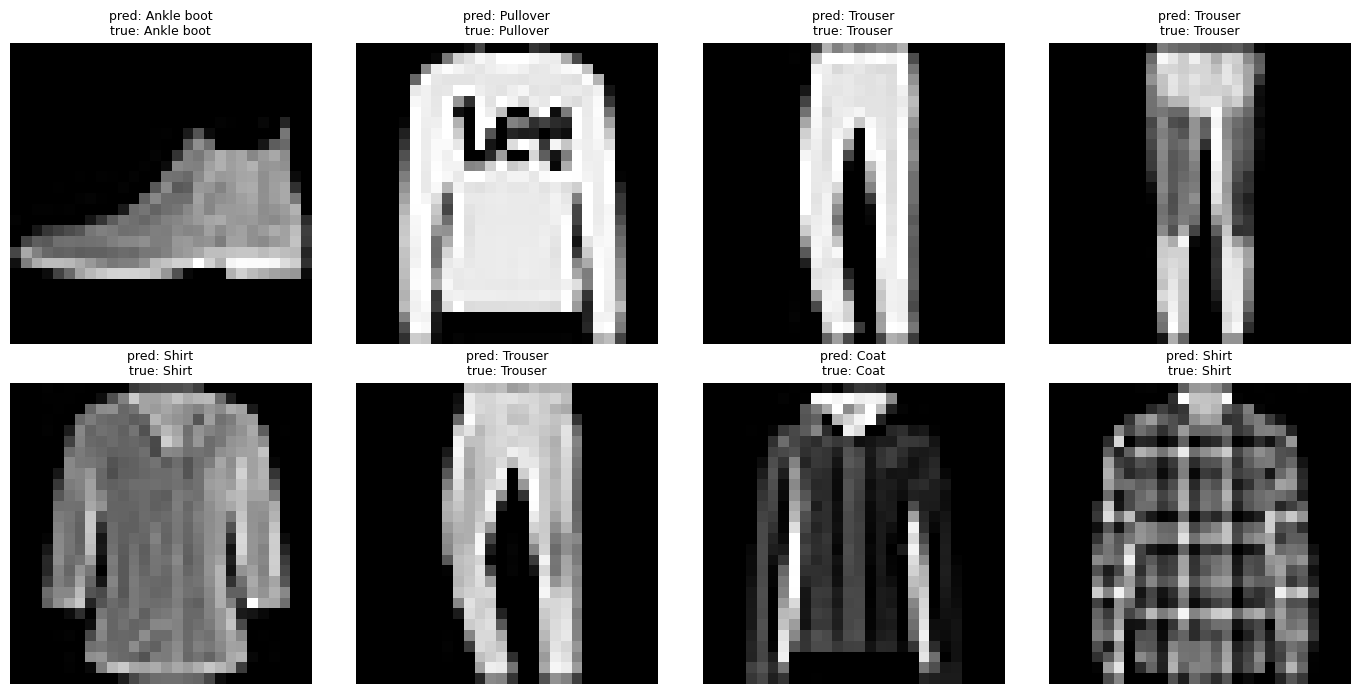

Mistakes in first 8 images: 0

B5
Accuracy before saving: 0.8957
Accuracy after loading: 0.8957
Same accuracy: True

C1 - Learning Rate 0.1
Epoch 1 loss: 0.5215691820279494
Epoch 2 loss: 0.34640976823945796
Epoch 3 loss: 0.31536237341858175
Accuracy: 0.873

C1 - Learning Rate 0.001
Epoch 1 loss: 1.4037412045988193
Epoch 2 loss: 0.6323248251224123
Epoch 3 loss: 0.5508400462011793
Accuracy: 0.7952

C2 - Adam Optimizer
Epoch 1 loss: 0.5212556280132169
Epoch 2 loss: 0.3185218699864233
Epoch 3 loss: 0.2774457451996646
Adam accuracy: 0.8925
SGD baseline accuracy: 0.8757

C3 - Batch Size 16
Epoch 1 loss: 0.49220122923888265
Epoch 2 loss: 0.3024751633092761
Epoch 3 loss: 0.2611658956012378
Training time: 153.3373086452484
Accuracy: 0.8915

C3 - Batch Size 256
Epoch 1 loss: 1.1173022904294603
Epoch 2 loss: 0.5387681022603461
Epoch 3 loss: 0.44483123104623024
Training time: 126.2909722328186
Accuracy: 0.8322

C4 - MLP vs CNN
Epoch 1 loss: 0.6296238553549435
Epoch 2 loss: 0.4373098062490349
Epoch

In [1]:

import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import pandas as pd
import time
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

torch.manual_seed(0)

tf = transforms.ToTensor()

train_data = datasets.FashionMNIST(
    "data", train=True, download=True, transform=tf
)

test_data = datasets.FashionMNIST(
    "data", train=False, download=True, transform=tf
)

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64)

classes = [
    "T-shirt", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("A1")
print("Train images:", len(train_data))
print("Test images:", len(test_data))

print("\nA2")
images, labels = next(iter(train_loader))
print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

print("\nA3")
fig, axes = plt.subplots(1, 8, figsize=(16, 3))

for i in range(8):
    axes[i].imshow(images[i].squeeze(), cmap="gray")
    axes[i].set_title(classes[labels[i].item()], fontsize=9)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

print("\nA4")
loss_fn = nn.CrossEntropyLoss()
logits = torch.tensor([[2.0, 1.0, 0.1]])

target_0 = torch.tensor([0])
target_2 = torch.tensor([2])

loss_0 = loss_fn(logits, target_0)
loss_2 = loss_fn(logits, target_2)

print("Loss for target 0:", loss_0.item())
print("Loss for target 2:", loss_2.item())
print("Larger loss:", 0 if loss_0 > loss_2 else 2)


class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


def test_accuracy(model, loader):
    model.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for images, labels in loader:
            preds = model(images).argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    return correct / total


print("\nB1")
torch.manual_seed(0)
model = SimpleCNN()
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(
    model.parameters(), lr=0.01, momentum=0.9
)

for epoch in range(3):
    model.train()
    total_loss = 0

    for images, labels in train_loader:
        outputs = model(images)
        loss = loss_fn(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print("Epoch", epoch + 1, "loss:", total_loss / len(train_loader))


print("\nB2")
baseline_accuracy = test_accuracy(model, test_loader)
print("Trained model accuracy:", baseline_accuracy)

torch.manual_seed(0)
untrained_model = SimpleCNN()
untrained_accuracy = test_accuracy(untrained_model, test_loader)

print("Untrained model accuracy:", untrained_accuracy)


print("\nB3")
torch.manual_seed(0)
model = SimpleCNN()
optimizer = torch.optim.SGD(
    model.parameters(), lr=0.01, momentum=0.9
)

losses = []

for epoch in range(5):
    model.train()
    total_loss = 0

    for images, labels in train_loader:
        outputs = model(images)
        loss = loss_fn(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    losses.append(avg_loss)

    print("Epoch", epoch + 1, "loss:", avg_loss)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 6), losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.xticks(range(1, 6))
plt.grid(True)
plt.show()


print("\nB4")
model.eval()
images, labels = next(iter(test_loader))

with torch.no_grad():
    predictions = model(images).argmax(dim=1)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

mistakes = 0

for i, ax in enumerate(axes.flat):
    pred = predictions[i].item()
    true = labels[i].item()

    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(
        f"pred: {classes[pred]}\ntrue: {classes[true]}",
        fontsize=9
    )
    ax.axis("off")

    if pred != true:
        mistakes += 1

plt.tight_layout()
plt.show()

print("Mistakes in first 8 images:", mistakes)


print("\nB5")
accuracy_before = test_accuracy(model, test_loader)

torch.save(model.state_dict(), "model.pth")

new_model = SimpleCNN()
new_model.load_state_dict(
    torch.load("model.pth", map_location="cpu", weights_only=True)
)

accuracy_after = test_accuracy(new_model, test_loader)

print("Accuracy before saving:", accuracy_before)
print("Accuracy after loading:", accuracy_after)
print("Same accuracy:", accuracy_before == accuracy_after)


def train(model, optimizer, loader, epochs=3):
    loss_fn = nn.CrossEntropyLoss()

    for epoch in range(epochs):
        model.train()
        total_loss = 0

        for images, labels in loader:
            outputs = model(images)
            loss = loss_fn(outputs, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(
            "Epoch",
            epoch + 1,
            "loss:",
            total_loss / len(loader)
        )


results = [
    {
        "experiment": "Baseline SGD lr=0.01 batch=64",
        "test_accuracy": baseline_accuracy
    }
]


print("\nC1 - Learning Rate 0.1")
torch.manual_seed(0)
model_lr_01 = SimpleCNN()

optimizer_lr_01 = torch.optim.SGD(
    model_lr_01.parameters(),
    lr=0.1,
    momentum=0.9
)

train(model_lr_01, optimizer_lr_01, train_loader)

acc_lr_01 = test_accuracy(model_lr_01, test_loader)
print("Accuracy:", acc_lr_01)

results.append({
    "experiment": "SGD lr=0.1",
    "test_accuracy": acc_lr_01
})


print("\nC1 - Learning Rate 0.001")
torch.manual_seed(0)
model_lr_0001 = SimpleCNN()

optimizer_lr_0001 = torch.optim.SGD(
    model_lr_0001.parameters(),
    lr=0.001,
    momentum=0.9
)

train(model_lr_0001, optimizer_lr_0001, train_loader)

acc_lr_0001 = test_accuracy(model_lr_0001, test_loader)
print("Accuracy:", acc_lr_0001)

results.append({
    "experiment": "SGD lr=0.001",
    "test_accuracy": acc_lr_0001
})


print("\nC2 - Adam Optimizer")
torch.manual_seed(0)
model_adam = SimpleCNN()

optimizer_adam = torch.optim.Adam(
    model_adam.parameters(),
    lr=0.001
)

train(model_adam, optimizer_adam, train_loader)

acc_adam = test_accuracy(model_adam, test_loader)
print("Adam accuracy:", acc_adam)
print("SGD baseline accuracy:", baseline_accuracy)

results.append({
    "experiment": "Adam lr=0.001",
    "test_accuracy": acc_adam
})


print("\nC3 - Batch Size 16")
train_loader_16 = DataLoader(
    train_data, batch_size=16, shuffle=True
)

torch.manual_seed(0)
model_batch_16 = SimpleCNN()

optimizer_batch_16 = torch.optim.SGD(
    model_batch_16.parameters(),
    lr=0.01,
    momentum=0.9
)

start = time.time()
train(model_batch_16, optimizer_batch_16, train_loader_16)
time_16 = time.time() - start

acc_batch_16 = test_accuracy(model_batch_16, test_loader)

print("Training time:", time_16)
print("Accuracy:", acc_batch_16)

results.append({
    "experiment": "SGD batch=16",
    "test_accuracy": acc_batch_16
})


print("\nC3 - Batch Size 256")
train_loader_256 = DataLoader(
    train_data, batch_size=256, shuffle=True
)

torch.manual_seed(0)
model_batch_256 = SimpleCNN()

optimizer_batch_256 = torch.optim.SGD(
    model_batch_256.parameters(),
    lr=0.01,
    momentum=0.9
)

start = time.time()
train(model_batch_256, optimizer_batch_256, train_loader_256)
time_256 = time.time() - start

acc_batch_256 = test_accuracy(model_batch_256, test_loader)

print("Training time:", time_256)
print("Accuracy:", acc_batch_256)

results.append({
    "experiment": "SGD batch=256",
    "test_accuracy": acc_batch_256
})

train_loader = DataLoader(
    train_data, batch_size=64, shuffle=True
)


print("\nC4 - MLP vs CNN")
torch.manual_seed(0)

mlp = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

optimizer_mlp = torch.optim.SGD(
    mlp.parameters(),
    lr=0.01,
    momentum=0.9
)

train(mlp, optimizer_mlp, train_loader)

acc_mlp = test_accuracy(mlp, test_loader)

cnn_params = sum(
    p.numel() for p in model.parameters()
)

mlp_params = sum(
    p.numel() for p in mlp.parameters()
)

print("CNN accuracy:", baseline_accuracy)
print("MLP accuracy:", acc_mlp)
print("CNN parameters:", cnn_params)
print("MLP parameters:", mlp_params)

results.append({
    "experiment": "MLP SGD lr=0.01",
    "test_accuracy": acc_mlp
})


print("\nC5 - Final Results")
df = pd.DataFrame(results)

df = df.sort_values(
    by="test_accuracy",
    ascending=False
).reset_index(drop=True)

print(df.to_string(index=False))

print("\nBest experiment:")
print(df.iloc[0]["experiment"])
print("Best accuracy:", df.iloc[0]["test_accuracy"])

print("\nBatch size comparison:")
print("Batch 16 time:", time_16)
print("Batch 256 time:", time_256)
print("Batch 16 accuracy:", acc_batch_16)
print("Batch 256 accuracy:", acc_batch_256)
